In [2]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.set(style='whitegrid')

<Figure size 1000x600 with 0 Axes>

In [3]:
csv_path = os.path.join('..', '..', 'Dataset', 'DemandForecastingDataset', 'demand_forecasting.csv')
df = pd.read_csv(csv_path)
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [22]:
print('Columns : ', list(df.columns))

Columns :  ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand', 'Year', 'Month', 'Day', 'Weekday']


In [7]:
# df.dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  str    
 1   Store ID            76000 non-null  str    
 2   Product ID          76000 non-null  str    
 3   Category            76000 non-null  str    
 4   Region              76000 non-null  str    
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  str    
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  str    
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: float64(2), 

In [8]:
df['Date'] = pd.to_datetime(df['Date'])

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                76000 non-null  datetime64[us]
 1   Store ID            76000 non-null  str           
 2   Product ID          76000 non-null  str           
 3   Category            76000 non-null  str           
 4   Region              76000 non-null  str           
 5   Inventory Level     76000 non-null  int64         
 6   Units Sold          76000 non-null  int64         
 7   Units Ordered       76000 non-null  int64         
 8   Price               76000 non-null  float64       
 9   Discount            76000 non-null  int64         
 10  Weather Condition   76000 non-null  str           
 11  Promotion           76000 non-null  int64         
 12  Competitor Pricing  76000 non-null  float64       
 13  Seasonality         76000 non-null  str           
 14  E

In [11]:
df.isna().sum() # df.isna().sum().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [17]:
round(df.describe(), 2).T

,count,mean,min,25%,50%,75%,max,std
Date,76000,2023-01-15 12:00:00,2022-01-01 00:00:00,2022-07-09 18:00:00,2023-01-15 12:00:00,2023-07-24 06:00:00,2024-01-30 00:00:00,NaN
Inventory Level,76000.0,301.06,0.0,136.0,227.0,408.0,2267.0,226.51
Units Sold,76000.0,88.83,0.0,58.0,84.0,114.0,426.0,43.99
Units Ordered,76000.0,89.09,0.0,0.0,0.0,121.0,1616.0,162.4
Price,76000.0,67.73,4.74,32.0,64.5,95.83,228.03,39.38
Discount,76000.0,9.09,0.0,5.0,10.0,10.0,25.0,7.48
Promotion,76000.0,0.33,0.0,0.0,0.0,1.0,1.0,0.47
Competitor Pricing,76000.0,69.45,4.29,32.62,65.7,97.93,261.22,40.94
Epidemic,76000.0,0.2,0.0,0.0,0.0,0.0,1.0,0.4
Demand,76000.0,104.32,4.0,71.0,100.0,133.0,430.0,46.96


In [18]:
round(df.describe(include='object'), 2).T

C:\Users\Kiran\AppData\Local\Temp\ipykernel_11248\1158102391.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  round(df.describe(include='object'), 2).T


,count,unique,top,freq
Store ID,76000,5,S001,15200
Product ID,76000,20,P0001,3800
Category,76000,5,Groceries,30400
Region,76000,4,North,30400
Weather Condition,76000,4,Cloudy,24360
Seasonality,76000,4,Winter,21000


In [19]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

df['Day'] = df['Date'].dt.day
df['Weekday'] = df['Date'].dt.day_name()

df.head(3)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand,Year,Month,Day,Weekday
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115,2022,1,1,Saturday
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229,2022,1,1,Saturday
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157,2022,1,1,Saturday


In [23]:
df['Discount_Price'] = df['Price'] * (1 - df['Discount'] / 100)

df['Sell_Through_Rate'] = df['Units Sold'] / df['Inventory Level'] 

df['Sell_Through_Rate'].describe()

count    75594.000000
mean         0.437580
std          0.298007
min          0.003150
25%          0.190807
50%          0.350475
75%          0.642276
max          1.000000
Name: Sell_Through_Rate, dtype: float64

In [33]:
df.groupby('Category')['Demand'].agg(['mean', 'sum', 'std']).sort_values(by='sum', ascending=False)

,mean,sum,std
Category,,,
Electronics,97.482018,889036,40.557859
Toys,92.606955,985338,46.170390
Furniture,73.581140,1006590,32.336141
Clothing,112.619737,1369456,41.022968
Groceries,120.976447,3677684,48.362730


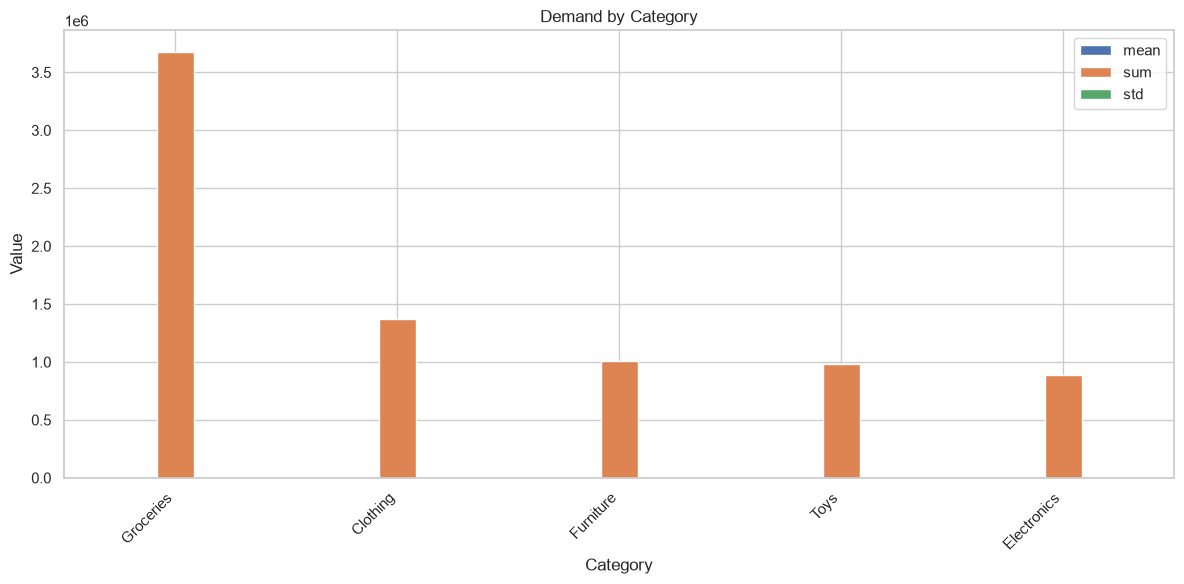

In [36]:
agg_df = df.groupby('Category')['Demand'].agg(['mean', 'sum', 'std']).sort_values(by='sum', ascending=False)

agg_df.plot(kind='bar', figsize=(12, 6))
plt.title('Demand by Category')
plt.ylabel('Value')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

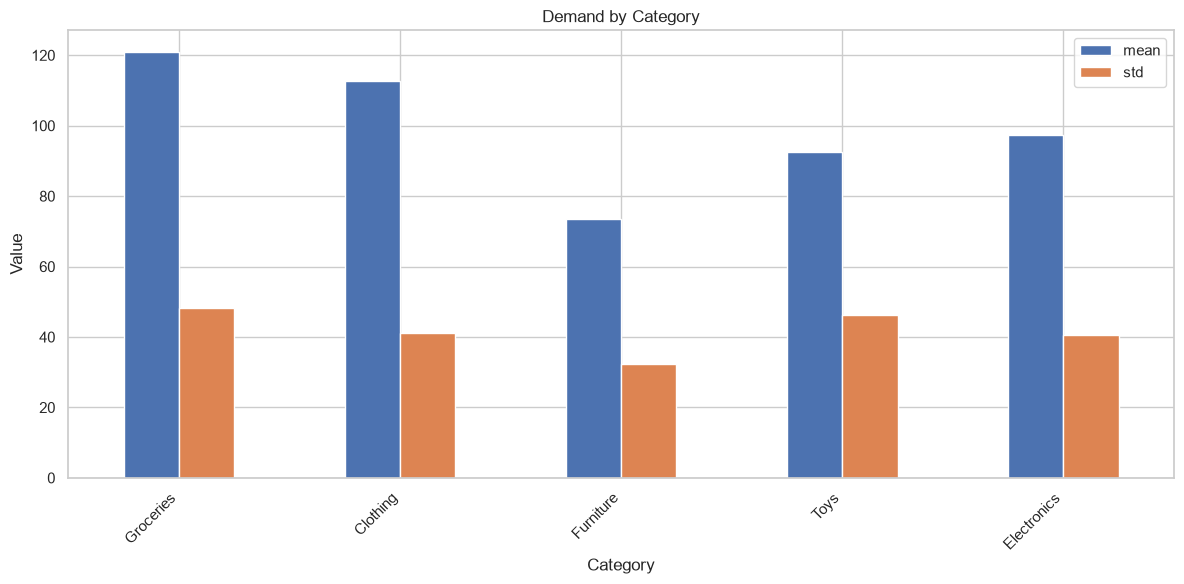

In [37]:
agg_df[['mean', 'std']].plot(kind='bar', figsize=(12, 6))
plt.title('Demand by Category')
plt.ylabel('Value')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [38]:
df.groupby(['Region', 'Seasonality'])['Demand'].mean()

Region  Seasonality
East    Autumn         106.353297
        Spring         100.168478
        Summer         115.388315
        Winter         104.273571
North   Autumn         103.065797
        Spring          97.399457
        Summer         112.843750
        Winter         102.017738
South   Autumn         104.464560
        Spring         100.328804
        Summer         115.089946
        Winter         107.733095
West    Autumn         100.165385
        Spring          93.219293
        Summer         108.111141
        Winter         100.988810
Name: Demand, dtype: float64

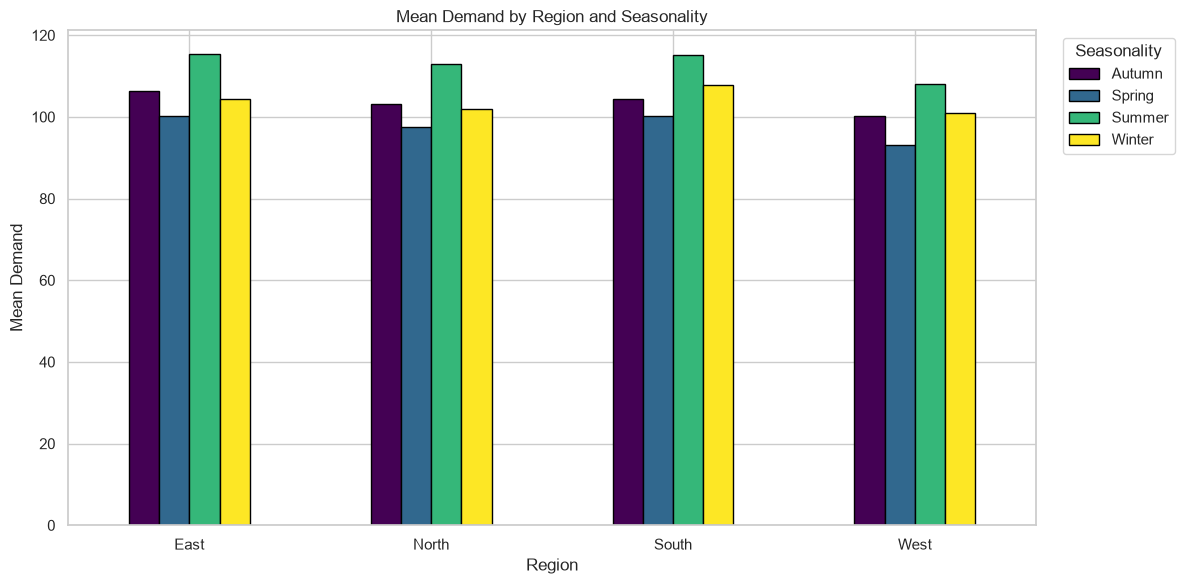

In [39]:
result = df.groupby(['Region', 'Seasonality'])['Demand'].mean()

pivot = result.unstack('Seasonality')   # rows = Region, cols = Seasonality

pivot.plot(kind='bar', figsize=(12, 6), colormap='viridis', edgecolor='black')
plt.title('Mean Demand by Region and Seasonality')
plt.ylabel('Mean Demand')
plt.xlabel('Region')
plt.xticks(rotation=0)
plt.legend(title='Seasonality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [40]:
df.groupby(['Promotion'])['Demand'].mean()

Promotion
0     95.026843
1    123.269400
Name: Demand, dtype: float64

In [43]:
pd.pivot_table(df, values='Demand', index='Month', columns='Category', aggfunc='mean')

Category,Clothing,Electronics,Furniture,Groceries,Toys
Month,,,,,
1,126.997962,99.519022,75.690821,117.399457,94.242236
2,128.966518,84.184524,61.625992,103.522768,68.885204
3,105.835685,108.120968,84.015233,126.561694,128.273041
4,106.972917,85.916667,63.005556,105.111250,85.753571
5,108.650202,79.577957,56.036738,98.637903,71.756912
6,105.670833,106.922222,79.908333,147.772500,100.825000
7,107.838710,87.418011,66.156810,128.744355,74.366359
8,107.871976,109.733871,83.524194,149.875403,102.794931
9,105.118750,105.015278,81.854630,122.239167,102.722619


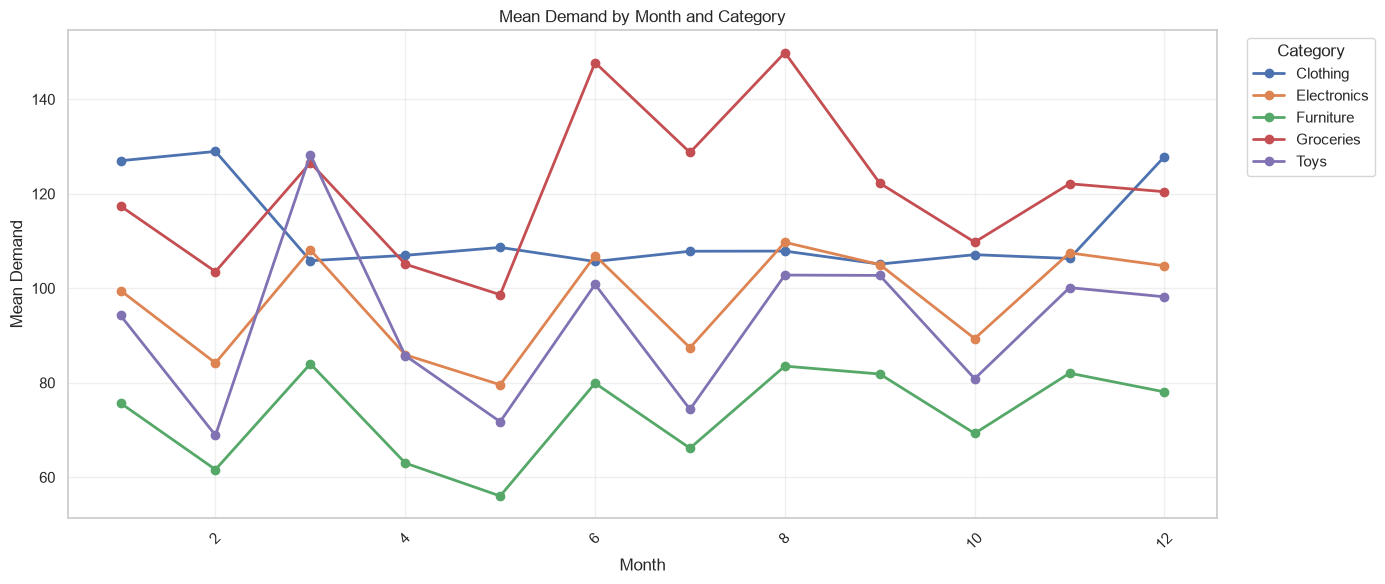

In [44]:
pivot = pd.pivot_table(df, values='Demand', index='Month', columns='Category', aggfunc='mean')

pivot.plot(kind='line', marker='o', figsize=(14, 6), linewidth=2)

plt.title('Mean Demand by Month and Category')
plt.xlabel('Month')
plt.ylabel('Mean Demand')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

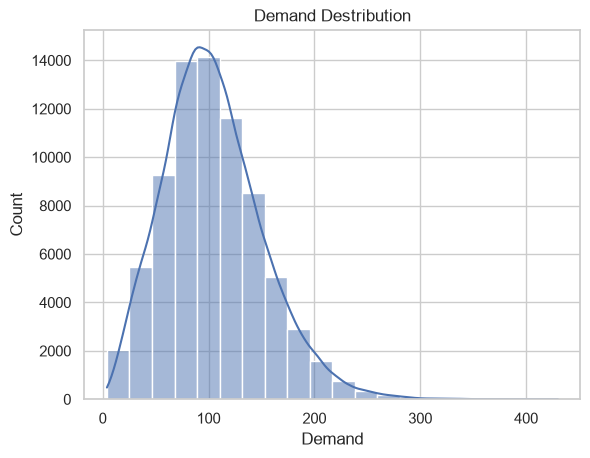

In [45]:
sns.histplot(df['Demand'], bins=20, kde=True)
plt.title('Demand Destribution')
plt.show()

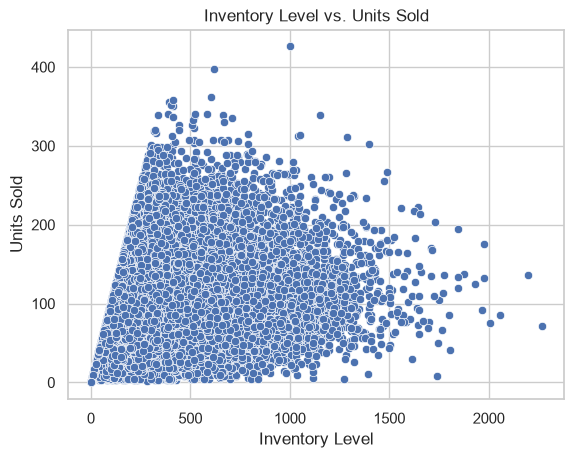

In [47]:
sns.scatterplot(data=df, x='Inventory Level', y='Units Sold')
plt.title('Inventory Level vs. Units Sold')
plt.show()

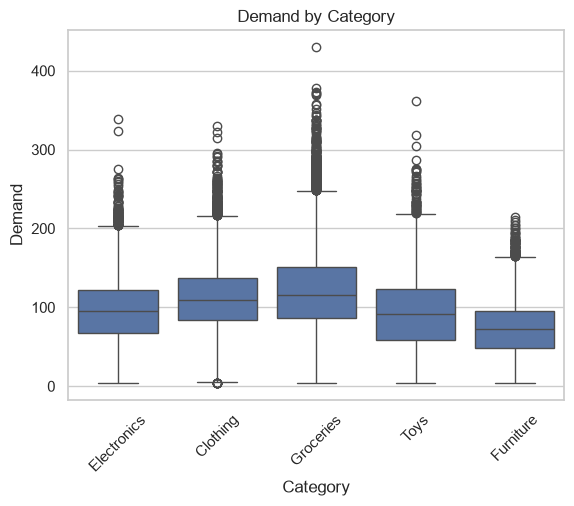

In [51]:
sns.boxplot(data=df, x='Category', y='Demand')
plt.xticks(rotation=45)
plt.title('Demand by Category')
plt.show()

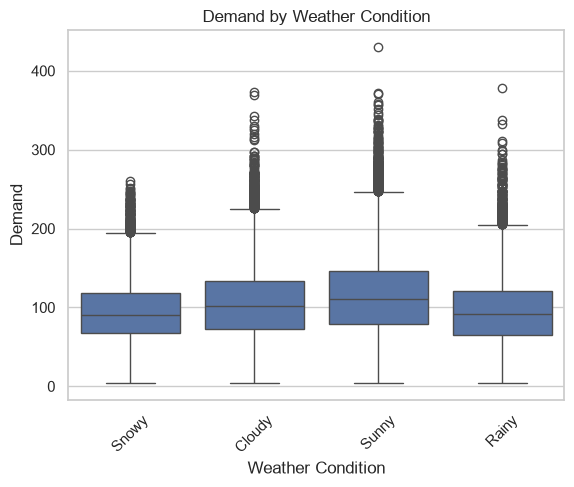

In [50]:
sns.boxplot(data=df, x='Weather Condition', y='Demand')
plt.xticks(rotation=45)
plt.title('Demand by Weather Condition')
plt.show()

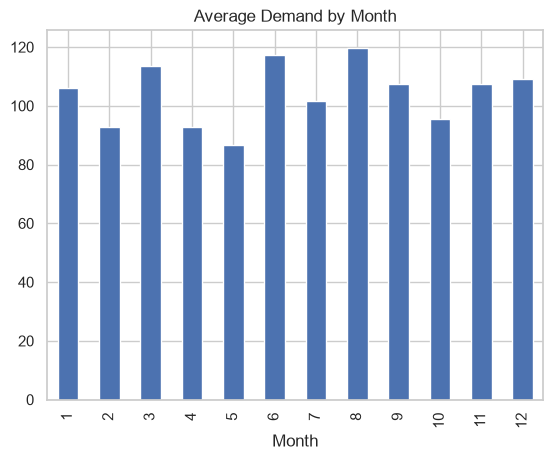

In [53]:
monthly_demand = df.groupby(['Month'])['Demand'].mean()

monthly_demand.plot(kind='bar')
plt.title('Average Demand by Month')
plt.show

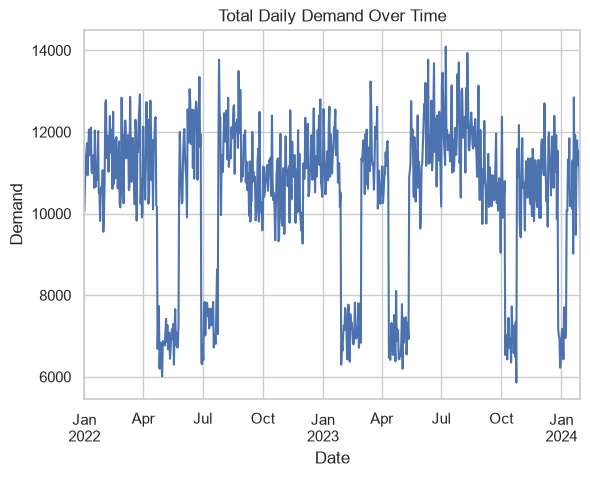

In [57]:
daily_demand = df.groupby(['Date'])['Demand'].sum()

daily_demand.plot()
plt.title('Total Daily Demand Over Time')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.show()

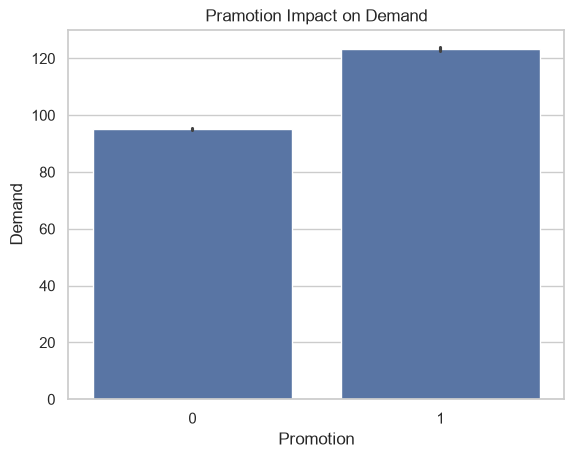

In [58]:
sns.barplot(data=df, x='Promotion', y='Demand')
plt.title('Pramotion Impact on Demand')
plt.show()

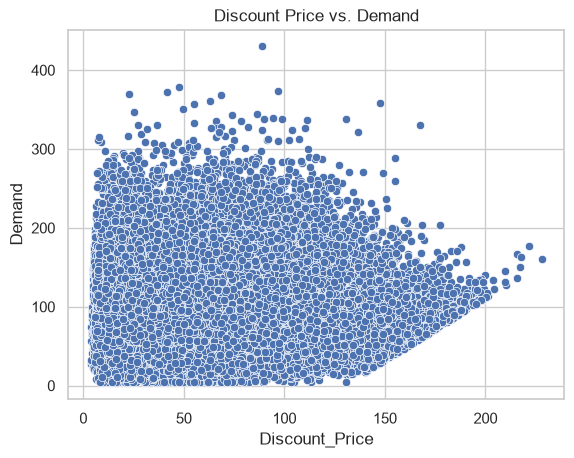

In [60]:
# ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 
#  'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand', 'Year', 'Month', 'Day', 'Weekday']

sns.scatterplot(data=df, x='Discount_Price', y='Demand')
plt.title('Discount Price vs. Demand')
plt.show()

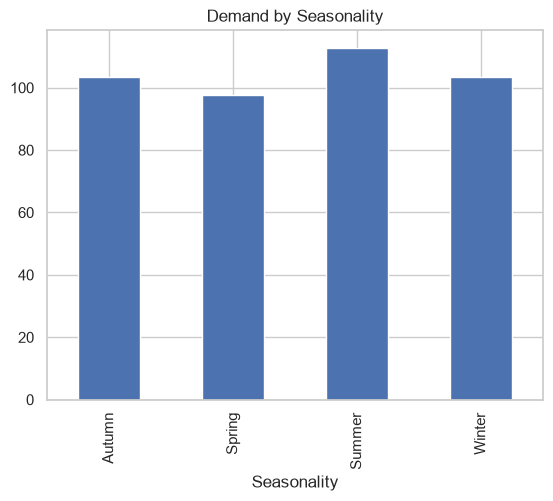

In [61]:
df.groupby(['Seasonality'])['Demand'].mean().plot(kind='bar', title='Demand by Seasonality')
plt.show()

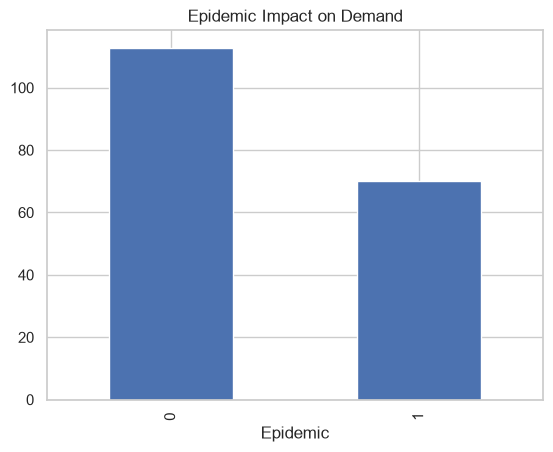

In [62]:
df.groupby(['Epidemic'])['Demand'].mean().plot(kind='bar', title='Epidemic Impact on Demand')
plt.show()

In [66]:
preprocess_file_path = os.path.join(os.path.dirname(csv_path), 'preprocess_demand_forecasting.csv')
df.to_csv(preprocess_file_path, index=False)

In [67]:
# df['Epidemic'].value_counts()